# DAY5 실습 04 — 상관계수 검정과 신뢰구간

In [5]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [6]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "auto_mpg.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `auto_mpg.csv`
출처 : UCI Machine Learning Repository - [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (CC BY 4.0). 생산지역(origin)을 1 · 2 · 3 대신 usa · europe · japan 으로 적은 판이다.

1970 ~ 1982년식 자동차 398대의 제원과 연비 자료다. 한 행은 **자동차 1대**다. 같은 행에 적힌 두 값을 **관측쌍** 하나로 본다.

| 열 이름 | 뜻 | 단위 |
|---|---|---|
| `mpg` | 연비. 클수록 연료를 덜 쓴다 | 마일/갤런 |
| `cylinders` | 실린더(기통) 수 | 개 |
| `displacement` | 배기량 | 세제곱인치 |
| `horsepower` | 마력. 결측 6건 | 마력 |
| `weight` | 무게 | 파운드 |
| `acceleration` | 가속시간 : 시속 0 → 60마일에 걸리는 시간. 클수록 느린 차 | 초 |
| `model_year` | 연식 (70 = 1970년) | 년 |
| `origin` | 생산지역 (usa · europe · japan) | 없음 |
| `name` | 차 이름 | 없음 |

**질문** : 표본에서 본 상관이 모집단에서도 0이 아니라고 말할 수 있는가? 피어슨과 스피어만 중 무엇으로 검정하는가?

**실습 전제** : 여기서는 자동차별 관측이 서로 독립이라고 가정한다.

In [7]:
# 행 · 열 수, 결측, 생산지역별 대수를 확인한다
print("행·열:", data.shape)
print(data.isna().sum())                     # 열마다 결측(빈 값) 개수. horsepower 에만 6건이 있다
print(data["origin"].value_counts())         # value_counts : 값마다 행 개수를 센다

행·열: (398, 9)
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
origin
usa       249
japan      79
europe     70
Name: count, dtype: int64


## 1. 표본상관계수 r과 모집단 상관계수 ρ

| 기호 | 읽기 | 뜻 |
|---|---|---|
| r | 알 | 표본상관계수 (가진 자료로 계산한 값) |
| ρ | 로 | 모집단 상관계수 (그리스 문자 rho) |
| ρs | 로 에스 | 스피어만 상관계수 |
| p | 피 | p값 (비율 검정에서는 모비율) |

가진 자료로 계산한 상관계수는 **표본상관계수** r이다. 우리가 알고 싶은 것은 모집단 전체의 상관계수인 **모집단 상관계수** ρ다. 표본을 다시 뽑으면 r도 달라지므로, r이 크다고 모집단 관계가 확정되지는 않는다.

| 대상 | 기호 | 뜻 | 확인 |
|---|---|---|---|
| 모집단 | ρ | 모집단의 피어슨 상관계수 | 표본만으로는 알 수 없다 |
| 표본 | r | 가진 자료로 계산한 상관계수 | 계산할 수 있다 |

모평균 μ를 표본평균 x̄로 추정하듯, ρ는 r로 추정한다. ρ에 대해 묻는 도구는 두 가지다.

| 도구 | 답하는 질문 |
|---|---|
| 검정 | ρ = 0이라고 가정할 때, 지금 같은 r이 나오는 것이 얼마나 드문가 (p값) |
| 신뢰구간 | ρ가 어느 범위에 있을 만한가 |

## 2. 상관계수 검정의 다섯 단계

**알고 싶은 관계를 먼저 정하고, 자료를 확인한 뒤 계산 · 검정 방법을 결정한다.** 정규성 검정 하나로 피어슨 · 스피어만을 자동 선택하지 않는다.

**목적 · 자료 확인 → 산점도와 방법 우선 선택 → 조건 확인 및 재검토 → 최종 가설 · 검정 → 보고**

| 단계 | 실제로 확인하는 것 |
|---|---|
| 1) 목적 · 자료 확인 | 원래 값의 **선형 관계**를 알고 싶은가, **순위상 증가 · 감소 관계**를 알고 싶은가? 한 행의 의미, 결측, 같은 대상의 반복 측정, 시간 순서, 집단 혼합을 확인한다 |
| 2) 산점도와 방법 우선 선택 | 직선 · 곡선 · 이상값 · 군집을 보고 방법을 우선 고른다. 필요하면 집단별로 나눠 본다 |
| 3) 조건 확인 및 재검토 | p값 · 신뢰구간을 구하려면 분포와 독립성까지 확인한다. 맞지 않으면 방법을 다시 정한다 |
| 4) 최종 가설 · 검정 | 최종 방법의 기호로 가설을 세우고, 그 방법의 함수로 검정한다 |
| 5) 결과 보고 | 계수 · 표본 수 · 산점도 모양과 함께 p값 · 신뢰구간, 해석의 한계를 보고한다 |

**조건 때문에 방법을 바꾸는 것은 괜찮다. 유의한 결과가 나오도록 방법을 고르지 않는다.** 방법은 상관검정의 p값을 보기 전에 정한다.

### 1) 목적 · 자료 확인

| 알고 싶은 관계 | 방법 |
|---|---|
| 원래 값이 직선처럼 함께 움직이는가 (선형 관계) | 피어슨 |
| 순위상 한쪽이 커질 때 다른 쪽이 계속 커지거나 작아지는가 (단조 관계) | 스피어만 |

| 자료 구조 | 확인할 것 |
|---|---|
| 한 행의 의미 | 한 행이 무엇 하나인가 (차 1대, 운전 기록 1건 등) |
| 결측 | 두 열 중 한쪽이라도 비면 그 짝은 쓸 수 없다 → 두 열을 같이 뽑아 `dropna` |
| 반복 측정 · 시간 순서 | 같은 대상을 여러 번 쟀거나 시간 순서로 이어진 기록인가 |
| 집단 혼합 | 성격이 다른 집단(생산지역, 기통 수, 라인 등)이 섞여 있는가 |

공식 문서 : [pandas.DataFrame.dropna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html)

### 2) 산점도와 방법 우선 선택

| 문제에서 주어진 상황 · 산점도 | 우선 선택 |
|---|---|
| 피어슨 또는 스피어만을 사용하라고 지정 | 지정한 방법 |
| 수치형 자료, 직선 관계 | 피어슨 |
| 순서형 자료(만족도 1 ~ 5점 등), 또는 한 방향으로 휜 곡선 | 스피어만 |
| U자처럼 방향이 바뀜 | 두 계수만으로 관계를 판단하지 않는다. 산점도로 설명한다 |

두 계수를 모두 구해 비교하면 판단에 도움이 된다. 차이가 크면 산점도로 돌아가 곡선 · 이상값을 확인한다.

| 함수 | 기능 |
|---|---|
| `plt.scatter(x, y)` | 산점도를 그린다 |
| `x.corr(y)` · `x.corr(y, method="spearman")` | 피어슨 · 스피어만 상관계수만 구한다 (p값 없음) |

공식 문서 : [matplotlib.pyplot.scatter](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) · [pandas.Series.corr](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html)

### 3) 조건 확인 및 재검토
 **정규성은 검정 방법을 고를 때 참고하는 기준이다. 자료의 척도와 산점도 모양도 함께 고려한다.**

| 확인할 것 | 피어슨 | 스피어만 | 방법 |
|---|---|---|---|
| 정규성 | 확인한다 | 확인하지 않는다 (순위로 계산) | 두 변수 **각각** 정규성 검정 · 히스토그램 · Q-Q 플롯 |
| 관측끼리 독립 | 확인한다 | 확인한다 | 자료를 모은 방식으로 판단한다 |
| 이상값 | 확인한다 | 확인한다 | 산점도 |

조건이 맞지 않으면 되돌아가서 바꾼다. 다만 **목적을 유지하는지** 확인한다.

| 조건 확인 결과 | 재검토 |
|---|---|
| 큰 문제 없음 | 우선 선택을 그대로 쓴다 |
| 정규성에서 크게 벗어남 + 순위 관계를 봐도 목적이 충족된다 | 스피어만으로 바꾸고, 가설과 해석도 함께 바꾼다 |
| 정규성에서 크게 벗어남 + 선형 관계가 핵심이다 | 피어슨 r은 유지하고, 검정 · 신뢰구간 계산 방법을 재검토한다 |
| 이상값이 있다 | 측정 오류인지 실제 관측인지 확인하고, 포함 여부에 따른 결과 차이를 살핀다 |

"크게 벗어난다"는 그림으로 판단한다. 한쪽으로 길게 치우친 꼬리나 멀리 떨어진 점이 있으면 크게 벗어난 것이다. 표본이 크면 정규분포에서 작은 어긋남도 정규성 검정에서 기각될 수 있으므로, p값만으로 정하지 않는다.

| 함수 | 기능 |
|---|---|
| `stats.shapiro(x)` | 정규성 검정. 귀무가설은 '정규분포를 따른다'이다. `.pvalue`(p값). 5,000건이 넘으면 `stats.normaltest(x)` 대안  |
| `plt.hist(x, bins=20)` | 히스토그램을 그린다. bins 는 막대 개수 |
| `stats.probplot(x, dist="norm", plot=축)` | 정규 Q-Q 플롯을 그린다. 점이 직선을 따라가면 정규분포에 가깝다 |

공식 문서 : [scipy.stats.shapiro](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html) · [scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html)

### 4) 최종 가설 · 검정

최종 방법의 기호로 가설을 세운다.

| 최종 방법 | 가설 |
|---|---|
| 피어슨 | 귀무가설(H₀): 모집단에서 두 변수는 상관이 없다. (ρ = 0)<br>대립가설(H₁): 모집단에서 두 변수는 상관이 있다. (ρ ≠ 0) |
| 스피어만 | 귀무가설(H₀): 모집단에서 두 변수는 상관이 없다. (ρs = 0)<br>대립가설(H₁): 모집단에서 두 변수는 상관이 있다. (ρs ≠ 0) |

문장은 같고, 무엇을 검정하는지는 기호가 알려 준다. 피어슨(ρ)은 직선 관계의 상관(선형 상관)을, 스피어만(ρs)은 순위에 따른 단조 관계를 검정한다. 유의수준은 α = 0.05, 양측으로 둔다.

**검정통계량** : 표본에서 계산해 귀무가설과 얼마나 다른지를 나타내는 값이다. 상관계수 검정에서는 최종 방법의 상관계수(피어슨 r, 스피어만 ρs)를 그대로 쓴다(`.statistic`). 0에서 멀수록(절댓값이 클수록) p값이 작아진다.

| p값 | 통계적 결론 | 사실적 결론 |
|---|---|---|
| p < α | 귀무가설을 기각한다 | 모집단에서 두 변수는 상관이 있다고 볼 통계적 근거가 있다 |
| p ≥ α | 귀무가설을 기각하지 못한다 | 모집단에서 두 변수는 상관이 있다고 볼 통계적 근거가 부족하다. "상관이 없다"를 증명한 것이 아니다 |

- p값은 "H₀와 검정 가정 아래, 지금과 같거나 더 극단적인 값이 나올 확률"이다. H₀가 참일 확률이 아니다
- **신뢰구간**은 모집단 상관계수 ρ가 있을 만한 범위다. 0을 포함하면 모집단 상관의 방향(+ / −)도 판단하기 어렵다

| 함수 | 기능 |
|---|---|
| `stats.pearsonr(x, y)` | 피어슨 상관계수와 검정. `.statistic`(r) · `.pvalue`(p값) |
| `결과.confidence_interval(confidence_level=0.95)` | 모집단 상관계수 ρ의 95% 신뢰구간. `.low`(아래 끝) · `.high`(위 끝) |
| `stats.spearmanr(x, y)` | 스피어만 상관계수와 검정. `.statistic`(ρs) · `.pvalue`(p값) |

같은 계수라면 `corr()` 값과 `.statistic` 값은 같다.

스피어만도 p값으로 유의성을 검정한다. 검정 함수마다 결과에 들어 있는 값이 다르므로 공식 문서의 Returns(반환값)에서 확인한다.

공식 문서 : [scipy.stats.pearsonr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html) · [scipy.stats.spearmanr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)

### 5) 결과 보고

검정에서 기각해도 말할 수 있는 것은 **함께 움직이는 관계**까지다. 한쪽이 다른 쪽의 원인이라는 뜻은 아니다.

| 구분 | 뜻 |
|---|---|
| 상관 | 관측에서 두 변수가 함께 변하는 관계 |
| 인과 | 다른 조건이 같을 때 한 변수를 실제로 바꾸면 다른 변수가 달라지는 관계 |

**보고 항목** : 네 가지가 서로 다른 질문에 답한다.

| 항목 | 알려 주는 것 |
|---|---|
| n | 몇 쌍의 관측으로 계산했는가 |
| r 또는 ρs | 관계의 방향과 강도 |
| 95% 신뢰구간 | 모집단 상관계수가 있을 만한 범위 (피어슨) |
| p값 | 모집단 상관계수가 0이라고 할 때 지금 같은 값이 얼마나 드문가 |

**보고 문장** : 대상과 n, 계수의 종류와 값, 신뢰구간 · p값, 산점도 모양, 해석의 한계(관찰 범위, 가정)


## 3. 예제 1 : 피어슨으로 검정하기 (일본 차의 가속시간 · 연비)

**상황** : 개발팀이 "가속시간이 긴 차가 연비는 좋다"고 한다. ＼

In [8]:
# [예제 1] 1) 목적 · 자료 확인
# 목적 : 가속시간이 길수록 연비가 직선처럼 함께 높아지는가 (선형 관계) → 피어슨을 먼저 생각한다
japan = data[data["origin"] == "japan"]                    # 생산지역이 japan 인 행만 고른다 → 생산지역이 섞이지 않는다
japan_pair = japan[["acceleration", "mpg"]].dropna()       # 두 열을 함께 뽑아 같은 행의 짝(관측쌍)을 유지한다
print("일본 차:", len(japan), "대 / 결측 제거 후 관측쌍 n:", len(japan_pair))

# [결과]
# - 한 행 = 일본 차 1대, 두 열 모두 결측 없음 (79쌍)

일본 차: 79 대 / 결측 제거 후 관측쌍 n: 79


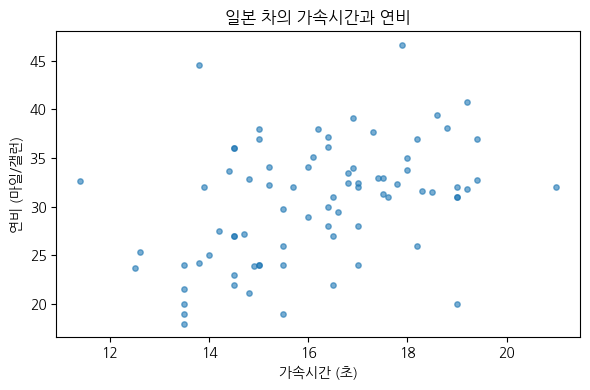

피어슨 r: 0.401 / 스피어만 ρs: 0.397


In [9]:
# [예제 1] 2) 산점도와 방법 우선 선택
x = japan_pair["acceleration"]               # x : 가로축 변수 (가속시간)
y = japan_pair["mpg"]                        # y : 세로축 변수 (연비)

plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=15, alpha=0.6)           # s : 점 크기, alpha : 투명도
plt.xlabel("가속시간 (초)")
plt.ylabel("연비 (마일/갤런)")
plt.title("일본 차의 가속시간과 연비")
plt.tight_layout()
plt.show()

print("피어슨 r:", round(x.corr(y), 3), "/ 스피어만 ρs:", round(x.corr(y, method="spearman"), 3))

# [결과]
# - 산점도 : 점이 넓게 퍼졌지만 오른쪽 위로 기운 띠다. 휜 곡선은 아니고 크게 떨어진 점도 없다
# - 두 계수 : 0.401 / 0.397 로 거의 같다
# - 우선 선택 : 피어슨

가속시간 (초) → shapiro p값: 0.529


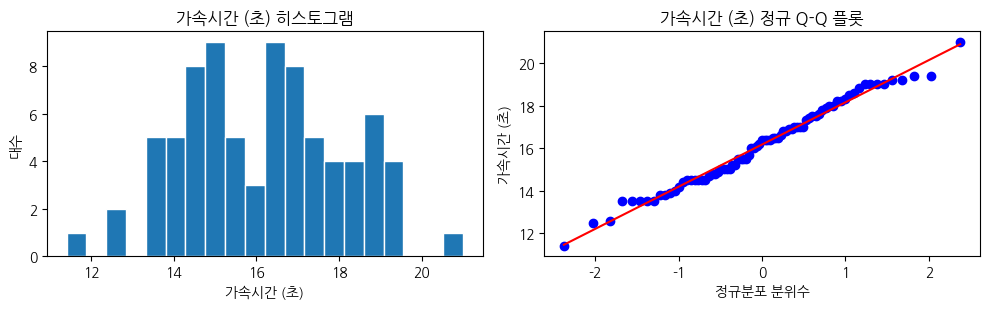

연비 (마일/갤런) → shapiro p값: 0.242


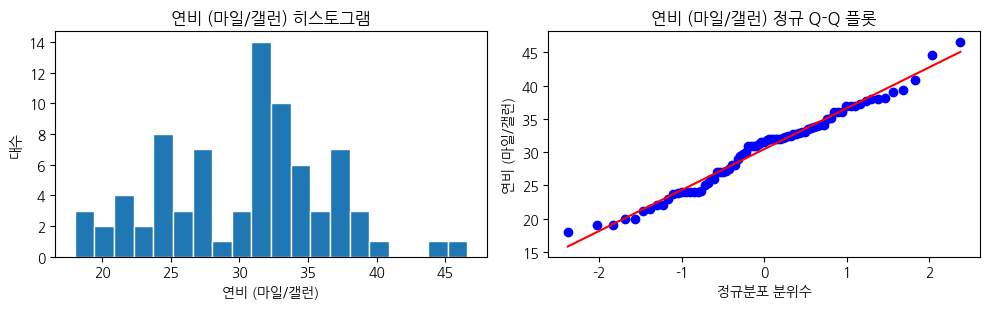

In [10]:
# [예제 1] 3) 조건 확인 및 재검토 : 피어슨이므로 두 변수의 정규성을 각각 확인한다
# 정규성 검정 p값과 히스토그램 · Q-Q 플롯을 한 번에 보는 함수를 만든다. 두 변수에 똑같이 쓴다
def check_normal(values, name):              # values 에 열을, name 에 그림 제목에 쓸 이름을 넣는다
    print(name, "→ shapiro p값:", round(stats.shapiro(values).pvalue, 3))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))          # subplots : 1행 2열, 칸 두 개를 만든다
    axes[0].hist(values, bins=20, edgecolor="white")            # 왼쪽 칸 : 히스토그램
    axes[0].set(title=name + " 히스토그램", xlabel=name, ylabel="대수")
    stats.probplot(values, dist="norm", plot=axes[1])           # 오른쪽 칸 : 정규 Q-Q 플롯
    axes[1].set(title=name + " 정규 Q-Q 플롯", xlabel="정규분포 분위수", ylabel=name)
    plt.tight_layout()
    plt.show()

check_normal(x, "가속시간 (초)")
check_normal(y, "연비 (마일/갤런)")
#   독립성 : 자동차별 관측이 서로 독립이라고 가정한다

# [결과]
# - 정규성 : shapiro p값이 가속시간 0.529, 연비 0.242 로 둘 다 0.05 이상이다. 히스토그램도 한쪽으로 크게 치우치지 않았다 → 큰 문제 없음
# - 독립성 : 자동차별 관측이 독립이라고 가정한다
# - 재검토 : 바꿀 이유가 없다 → 최종 방법은 피어슨

In [11]:
# [예제 1] 4) 최종 가설 · 검정 : 피어슨이므로 ρ 로 쓰고 stats.pearsonr 로 검정한다
# 귀무가설(H₀): 모집단에서 일본 차의 가속시간과 연비는 상관이 없다. (ρ = 0)
# 대립가설(H₁): 모집단에서 일본 차의 가속시간과 연비는 상관이 있다. (ρ ≠ 0)
alpha = 0.05          # 유의수준 α, 양측

japan_result = stats.pearsonr(x, y)
#   stats.pearsonr : 피어슨 상관계수와 검정을 한 번에 한다. 결과를 japan_result 에 담아 두고 필요한 값을 꺼내 쓴다
japan_ci = japan_result.confidence_interval(confidence_level=0.95)     # 95% 신뢰구간

print("r:", round(japan_result.statistic, 3))                             # .statistic : 상관계수 r (검정통계량)
print("p값:", round(japan_result.pvalue, 4), "/ p < α ?", japan_result.pvalue < alpha)   # True 이면 귀무가설을 기각한다
print("95% 신뢰구간:", round(japan_ci.low, 3), "~", round(japan_ci.high, 3))           # .low · .high : 아래 끝 · 위 끝

# [결과]
# - n = 79, r = 0.401, p = 0.0002, 95% 신뢰구간 0.198 ~ 0.572
# - 통계적 결론 : p = 0.0002 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 모집단에서 일본 차의 가속시간과 연비는 상관이 있다고 볼 통계적 근거가 있다.
#   가속시간이 긴 차일수록 연비가 높은 보통 정도의 양의 상관이 관찰되었다

r: 0.401
p값: 0.0002 / p < α ? True
95% 신뢰구간: 0.198 ~ 0.572


In [12]:
# [예제 1] 5) 결과 보고 : 보고 문장에 넣을 값을 모은다
print("대상 : 일본 차, 관측쌍 n =", len(japan_pair))
print("계수 : 피어슨 r =", round(japan_result.statistic, 3),
      "(95% 신뢰구간", round(japan_ci.low, 3), "~", round(japan_ci.high, 3), ", p =", round(japan_result.pvalue, 4), ")")
print("관찰 범위 : 가속시간", x.min(), "~", x.max(), "초")

# [결과]
# 보고 문장 : 일본 차 79대에서 가속시간과 연비는 피어슨 r = 0.401 (95% 신뢰구간 0.198 ~ 0.572, p = 0.0002)으로
#            보통 정도의 양의 상관이 관찰되었다. 산점도는 넓게 퍼진 오른쪽 위 방향의 띠다. 가속시간 11.4 ~ 21.0초 구간의 관찰자료이며,
#            자동차별 관측이 독립이라고 가정한 계산이다. 가속시간이 연비의 원인이라고 보지 않는다

대상 : 일본 차, 관측쌍 n = 79
계수 : 피어슨 r = 0.401 (95% 신뢰구간 0.198 ~ 0.572 , p = 0.0002 )
관찰 범위 : 가속시간 11.4 ~ 21.0 초


## 4. 예제 2 : 스피어만으로 검정하기 (마력 · 연비)

**상황** : 마력이 높은 차는 연비가 낮은가? 전체 자동차로 확인한다. 예제 1과 같은 다섯 단계로 하되, 2)에서 고른 방법이 달라지면 3) ~ 5)가 어떻게 따라 바뀌는지 본다.

In [13]:
# [예제 2] 1) 목적 · 자료 확인（마력(HP): 엔진이 단위 시간에 발휘하는 출력）
# 목적 : 마력이 높을수록 연비가 계속 낮아지는가 (순위상 감소 관계로도 목적이 충족된다)
print("결측 :", data[["horsepower", "mpg"]].isna().sum().to_dict())    # 마력에만 결측 6건
hp_pair = data[["horsepower", "mpg"]].dropna()
#   두 열을 먼저 한 표로 뽑고 dropna 한다 → 한쪽이라도 빈 행은 짝째 빠진다
#   마력만 dropna 하면 연비와 길이가 달라져(392 vs 398) 짝이 어긋난다
print("제거 전", len(data), "대 → 제거 후", len(hp_pair), "대")

# [결과]
# - 한 행 = 자동차 1대, 마력 결측 6대를 짝째 빼서 392쌍
# - 생산지역 세 곳이 섞여 있다 (집단 혼합) → 2) 산점도에서 모양을 함께 본다

결측 : {'horsepower': 6, 'mpg': 0}
제거 전 398 대 → 제거 후 392 대


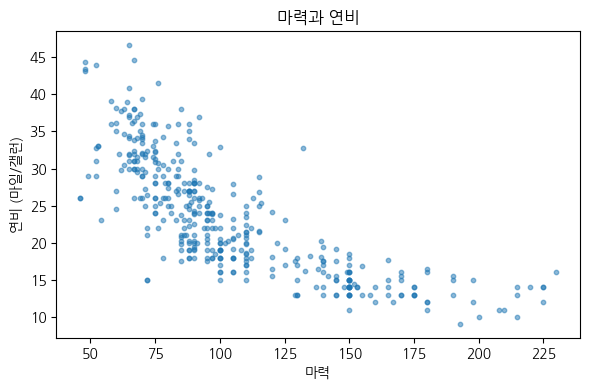

피어슨 r: -0.778 / 스피어만 ρs: -0.854


In [14]:
# [예제 2] 2) 산점도와 방법 우선 선택
x = hp_pair["horsepower"]                    # 예제 1 의 x, y 를 새 값으로 바꾼다
y = hp_pair["mpg"]

plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=10, alpha=0.5)
plt.xlabel("마력")
plt.ylabel("연비 (마일/갤런)")
plt.title("마력과 연비")
plt.tight_layout()
plt.show()

print("피어슨 r:", round(x.corr(y), 3), "/ 스피어만 ρs:", round(x.corr(y, method="spearman"), 3))

# [결과]
# - 산점도 : 오른쪽 아래로 내려가는데 직선이 아니라 한 방향으로 휜 곡선이다 (마력이 낮은 쪽에서 급하게, 높은 쪽에서 완만하게 내려간다)
# - 두 계수 : 피어슨 −0.778, 스피어만 −0.854 로 스피어만의 절댓값이 더 크다 (휜 곡선이라 피어슨이 작게 나온다)
# - 우선 선택 : 스피어만

In [15]:
# [예제 2] 3) 조건 확인 및 재검토
# - 정규성 : 스피어만은 순위로 계산하므로 확인하지 않는다
# - 독립성 : 자동차별 관측이 서로 독립이라고 가정한다
# - 이상값 : 2) 산점도에서 무리에서 크게 떨어진 점은 없다
# - 재검토 : → 최종 방법은 스피어만

In [28]:
# [예제 2] 4) 최종 가설 · 검정 : 스피어만이므로 ρs 로 쓰고 stats.spearmanr 로 검정한다. 순위에 따른 단조 관계를 검정한다
# 귀무가설(H₀): 모집단에서 자동차의 마력과 연비는 상관이 없다. (ρs = 0)
# 대립가설(H₁): 모집단에서 자동차의 마력과 연비는 상관이 있다. (ρs ≠ 0)
alpha = 0.05          # 유의수준 α, 양측

hp_result = stats.spearmanr(x, y)
#   stats.spearmanr : 스피어만 상관계수와 검정을 한 번에 한다

print("ρs:", round(hp_result.statistic, 3))                   # .statistic : 스피어만 상관계수 ρs (검정통계량)
print("p값:", hp_result.pvalue,)
#   p값이 1.6e-112 처럼 나오면 10 의 −112 제곱을 곱한 아주 작은 수다 → p < 0.001 로 적는다


# [결과]
# - n = 392, ρs = −0.854, p < 0.001
# - 통계적 결론 : p < 0.001 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 모집단에서 자동차의 마력과 연비는 상관이 있다고 볼 통계적 근거가 있다.
#   마력이 높은 차일수록 연비가 낮은 강한 음의 상관이 관찰되었다

ρs: -0.854
p값: 1.619383245501938e-112
참고 피어슨 r: -0.778


In [29]:
# [예제 2] 5) 결과 보고 : 보고 문장에 넣을 값을 모은다
print("대상 : 자동차 (마력 결측 6대 제외), 관측쌍 n =", len(hp_pair))
print("계수 : 스피어만 ρs =", round(hp_result.statistic, 3), "(p < 0.001)")
print("관찰 범위 : 마력", x.min(), "~", x.max())

# [결과]
# 보고 문장 : 자동차 392대(마력 결측 6대 제외)에서 마력과 연비는 스피어만 ρs = −0.854 (p < 0.001)으로
#            강한 음의 상관이 관찰되었다. 산점도는 직선이 아니라 한 방향으로 휜 곡선이다(참고 피어슨 r = −0.778).
#            마력 46 ~ 230 구간의 관찰자료이며, 자동차별 관측이 독립이라고 가정한 계산이다. 마력이 연비의 원인이라고 보지 않는다

대상 : 자동차 (마력 결측 6대 제외), 관측쌍 n = 392
계수 : 스피어만 ρs = -0.854 (p < 0.001)
관찰 범위 : 마력 46.0 ~ 230.0


## 5. 문제 : 직접 골라서 검정하기

예제와 같은 다섯 단계로 푼다. **어느 방법을 쓸지는 2)에서 산점도를 보고 우선 고르고, 3)에서 조건을 확인해 최종 방법을 정한다.** 정규성 확인에는 예제 1의 `check_normal` 함수를 쓴다.

In [18]:
# 문제 1-1) 목적 · 자료 확인
# 상황 : 미국의 4기통 차만 모아, 무게가 무거운 차일수록 가속시간이 직선처럼 함께 달라지는지 본다.
# origin 이 usa 이고 cylinders 가 4 인 차를 고르고, 무게 · 가속시간 두 열로 관측쌍을 만든 뒤 대수와 결측을 확인하시오.
# 힌트 : 두 조건을 함께 쓸 때는 data[(조건1) & (조건2)] 처럼 조건마다 괄호로 묶는다



In [19]:
# 문제 1-2) 산점도와 방법 우선 선택
# 무게(x)와 가속시간(y)의 산점도를 그리고 두 계수를 구한 뒤, 방법을 우선 고르시오.



In [20]:
# 문제 1-3) 조건 확인 및 재검토
# 우선 고른 방법에 필요한 조건을 확인하고, 최종 방법을 정하시오.



In [21]:
# 문제 1-4) 최종 가설 · 검정
# 최종 방법에 맞게 가설을 한글 문장과 기호로 쓰고, 계수 · p값 · (피어슨이면) 95% 신뢰구간을 구해 통계적 결론과 사실적 결론을 쓰시오.



In [22]:
# 문제 1-5) 결과 보고
# 보고 문장에 넣을 값(대상과 n, 계수 · 신뢰구간 · p값, 관찰 범위)을 출력하고, 보고 문장을 쓰시오.



In [23]:
# 문제 2-1) 목적 · 자료 확인
# 상황 : 무거운 차일수록 연비가 계속 낮아지는지 전체 자동차로 확인한다.
# 무게 · 연비 두 열로 관측쌍을 만들고 대수와 결측을 확인하시오.



In [24]:
# 문제 2-2) 산점도와 방법 우선 선택
# 무게(x)와 연비(y)의 산점도를 그리고 두 계수를 구한 뒤, 방법을 우선 고르시오.



In [25]:
# 문제 2-3) 조건 확인 및 재검토
# 우선 고른 방법에 필요한 조건을 확인하고, 최종 방법을 정하시오. 확인하지 않는 조건이 있으면 그 이유를 쓰시오.



In [26]:
# 문제 2-4) 최종 가설 · 검정
# 최종 방법에 맞게 가설을 한글 문장과 기호로 쓰고, 계수와 p값을 구해(참고값으로 피어슨 r 도 출력) 통계적 결론과 사실적 결론을 쓰시오.



In [27]:
# 문제 2-5) 결과 보고
# 보고 문장에 넣을 값(대상과 n, 계수 · p값, 관찰 범위)을 출력하고, 보고 문장을 쓰시오.



## 6. 정리 : 상관계수 검정

**목적 · 자료 확인 → 산점도와 방법 우선 선택 → 조건 확인 및 재검토 → 최종 가설 · 검정 → 보고**

| 단계 | 피어슨 | 스피어만 |
|---|---|---|
| 1) 목적 | 원래 값의 선형 관계 | 순위상 증가 · 감소 관계 (단조 관계) |
| 2) 우선 선택 | 수치형, 산점도가 직선 | 한 방향으로 휜 곡선, 또는 순서형 자료 |
| 3) 조건 확인 | 정규성 (두 변수 각각), 독립성, 이상값 | 독립성, 이상값 |
| 재검토 | 정규성에서 크게 벗어나면 : 순위 관계로 목적이 충족되면 스피어만으로 바꾼다 | |
| 4) 가설 | H₀: 모집단에서 상관이 없다 (ρ = 0) / H₁: ρ ≠ 0 | H₀: 모집단에서 상관이 없다 (ρs = 0) / H₁: ρs ≠ 0 |
| 검정 코드 | `stats.pearsonr(x, y)` → `.statistic` · `.pvalue` · `.confidence_interval()` | `stats.spearmanr(x, y)` → `.statistic` · `.pvalue` |
| 결론 | p < 0.05 → 기각 / p ≥ 0.05 → 기각하지 못한다 (근거가 부족하다) | 같다 |
| 5) 결과 보고 | n · r · 신뢰구간 · p값 · 모양 · 한계 · 인과 아님 | n · ρs · p값 · 모양 · 한계 · 인과 아님 |

### 해석 시 유의점

- 알고 싶은 관계를 먼저 정한다. 정규성 검정 하나로 피어슨 · 스피어만을 자동 선택하지 않는다
- 정규성은 검정 방법을 고를 때 참고하는 기준이다. 자료의 척도와 산점도 모양도 함께 고려한다
- 조건 때문에 방법을 바꾸는 것은 괜찮다. 유의한 결과가 나오도록 방법을 고르지 않는다
- 관측끼리 독립이 아니면(반복 측정 · 시간 순서) 스피어만으로 바꿔도 해결되지 않는다. 결과 보고에 한계로 적는다
- 결측이 있으면 두 열을 같이 뽑아 `dropna` 한 뒤 검정한다
- 결과에는 n · 계수 · 신뢰구간 · p값을 함께 적는다. 기각하지 못하면 "상관이 있다고 볼 근거가 부족하다"로 쓴다
- 기각해도 관계까지다. 원인이라고 말하지 않는다

## 참고 : 관측쌍 수가 p값과 신뢰구간에 주는 영향

**p값은 관측쌍 수 n에 따라 달라진다. 관계가 얼마나 강한지는 r과 신뢰구간으로 판단한다

**1) n이 크면 아주 작은 r도 유의하다** (공기온도 · 회전수)

| n | r | p값 | 95% 신뢰구간 |
|---|---|---|---|
| 10,000 | 0.023 | 0.023 | 0.003 ~ 0.042 |

- p < 0.05라서 귀무가설을 기각한다. 하지만 r 0.023은 관계가 거의 없는 수준이다.
- 읽을 점 : "유의하다"는 "0이 아니다"일 뿐 "강하다"가 아니다.

**2) r이 비슷해도 n이 작으면 신뢰구간이 넓다** (공기온도 · 공정온도에서 무작위로 뽑은 관측쌍)

| n | r | 95% 신뢰구간 | 폭 |
|---|---|---|---|
| 30 | 0.835 | 0.678 ~ 0.919 | 0.240 |
| 300 | 0.863 | 0.830 ~ 0.889 | 0.059 |
| 10,000 | 0.876 | 0.871 ~ 0.881 | 0.009 |

- 세 경우 모두 p < 0.001이라 p값만 보면 차이가 보이지 않는다. r도 거의 그대로이고, 달라진 것은 신뢰구간 폭이다.
- 읽을 점 : n이 작으면 ρ가 어디쯤인지 좁히지 못한다.

그래서 결과에는 p값만 적지 않고 n · r · 신뢰구간을 함께 적는다.

**3) 표본이 크면 정규분포에서 작은 어긋남도 기각될 수 있다** (AI4I 공기온도 10,000건)

- normaltest p값이 1.0e-223으로 기각되지만, 히스토그램 · Q-Q 플롯을 보면 양 끝이 조금 짧은 정도다.
- 읽을 점 : 표본이 큰 자료에서는 정규성 검정의 p값만으로 피어슨 · 스피어만을 자동으로 정하지 않는다. 그림으로 "크게 어긋나는가"를 함께 본다.